<a href="https://colab.research.google.com/github/efitznm/Data-Science-Portfolio-C22/blob/main/Modules/Module_2_Regression/Projects/Instructions/Project.2-Housing/Housing-Pass-12.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Project 2 - Pass 12: Housing Price Prediction






The project should be done using Regression prediction techniques ( with feature scaling and regularization ) as covered in class.
The goal is to minimize the RMS ***percentage*** error ( root mean squared percentage error - RMSPE ) on your prediction of the house sales price.



Any of the available features can be used in the regression, but a minimum set of variables that do the job should be the ultimate goal.



Be sure to go through the whole data science process and document as such in your Jupyter notebook.



This project will have less direct "To Do" guidance and the progression through the data science process will be more individualized this time around.  We will talk about all the issues during class so you're not going to be out on a ledge with this one, I just want to move you towards performing a data science project on your own eventually.

There are two parts to this data set, both of which are on AWS:

- [Housing Data Dictionary]( https://ddc-datascience.s3.amazonaws.com/Projects/Project.2-Housing/Housing%20-%20Data%20Documentation.pdf )
- [Data Set]( https://ddc-datascience.s3.amazonaws.com/Projects/Project.2-Housing/Data/Housing.Data.csv)


In [1]:
! curl -s -I https://ddc-datascience.s3.amazonaws.com/Projects/Project.2-Housing/Data/Housing.Data.csv

HTTP/1.1 200 OK
x-amz-id-2: hLaF93vxrJHksHd2fltA6/A9HjabIG+kPBMIeu67ByQfJjYNtRphC8ILkFy2EdedRUtQuoMgrH35N8beujEbqXkI1t/hr3mw
x-amz-request-id: SCK0RD0B5D72W63G
Server: AmazonS3
Date: Wed, 28 Oct 2026 21:09:18 GMT
Last-Modified: Fri, 06 Oct 2023 04:00:27 GMT
ETag: "76e84c9ee7f6fd4d51276697f81e76e1"
x-amz-server-side-encryption: AES256
Accept-Ranges: bytes
Content-Length: 880420
Content-Type: text/csv



In [2]:
! curl -s https://ddc-datascience.s3.amazonaws.com/Projects/Project.2-Housing/Data/Housing.Data.csv | head -2

PID,MS SubClass,MS Zoning,Lot Frontage,Lot Area,Street,Alley,Lot Shape,Land Contour,Utilities,Lot Config,Land Slope,Neighborhood,Condition 1,Condition 2,Bldg Type,House Style,Overall Qual,Overall Cond,Year Built,Year Remod/Add,Roof Style,Roof Matl,Exterior 1st,Exterior 2nd,Mas Vnr Type,Mas Vnr Area,Exter Qual,Exter Cond,Foundation,Bsmt Qual,Bsmt Cond,Bsmt Exposure,BsmtFin Type 1,BsmtFin SF 1,BsmtFin Type 2,BsmtFin SF 2,Bsmt Unf SF,Total Bsmt SF,Heating,Heating QC,Central Air,Electrical,1st Flr SF,2nd Flr SF,Low Qual Fin SF,Gr Liv Area,Bsmt Full Bath,Bsmt Half Bath,Full Bath,Half Bath,Bedroom AbvGr,Kitchen AbvGr,Kitchen Qual,TotRms AbvGrd,Functional,Fireplaces,Fireplace Qu,Garage Type,Garage Yr Blt,Garage Finish,Garage Cars,Garage Area,Garage Qual,Garage Cond,Paved Drive,Wood Deck SF,Open Porch SF,Enclosed Porch,3Ssn Porch,Screen Porch,Pool Area,Pool QC,Fence,Misc Feature,Misc Val,Mo Sold,Yr Sold,Sale Type,Sale Condition,SalePrice
905101070,20,RL,62.0,14299,Pave,,Reg,Lvl,AllPub,Inside,G

## Problem Definition

### Business Problem

Help investors evaluate whether float features might be a useful factor when assessing a property's potential market value.

### Data Science Problem

Supervised regression

## Data Collection/Sources

### Load Modules

In [3]:
# Import the libraries and modules
from IPython.display import Image

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import plotly.express as px
import seaborn as sns
import statsmodels.api as sm

from sklearn import datasets, metrics, model_selection
from sklearn.linear_model import LinearRegression, Ridge, Lasso
from sklearn.model_selection import cross_val_score, train_test_split
from sklearn.metrics import mean_squared_error
from sklearn.preprocessing import StandardScaler

### Load Data

In [4]:
# Define the data's url as 'url'
url = 'https://ddc-datascience.s3.amazonaws.com/Projects/Project.2-Housing/Data/Housing.Data.csv'    # insert url here
url

'https://ddc-datascience.s3.amazonaws.com/Projects/Project.2-Housing/Data/Housing.Data.csv'

In [5]:
# Define the data frame as 'df'
df = pd.read_csv(url)

## Data Cleaning

### Overview

In [6]:
# Display the head - 81 columns
df.head()

,PID,MS SubClass,MS Zoning,Lot Frontage,Lot Area,Street,Alley,Lot Shape,Land Contour,Utilities,...,Pool Area,Pool QC,Fence,Misc Feature,Misc Val,Mo Sold,Yr Sold,Sale Type,Sale Condition,SalePrice
0,905101070,20,RL,62.0,14299,Pave,NaN,Reg,Lvl,AllPub,...,0,NaN,MnPrv,NaN,0,7,2007,WD,Normal,115400
1,905101330,90,RL,72.0,10791,Pave,NaN,Reg,Lvl,AllPub,...,0,NaN,NaN,Shed,500,10,2006,WD,Normal,90000
2,903454090,50,RM,50.0,9000,Pave,NaN,Reg,Bnk,AllPub,...,0,NaN,NaN,NaN,0,12,2007,WD,Normal,141000
3,533244030,60,FV,68.0,7379,Pave,NaN,IR1,Lvl,AllPub,...,0,NaN,NaN,NaN,0,4,2010,WD,Normal,254000
4,909252020,70,RL,60.0,7200,Pave,NaN,Reg,Lvl,AllPub,...,0,NaN,MnPrv,NaN,0,4,2009,WD,Normal,155000


In [7]:
# Display the tail - target is the last row
df.tail()

,PID,MS SubClass,MS Zoning,Lot Frontage,Lot Area,Street,Alley,Lot Shape,Land Contour,Utilities,...,Pool Area,Pool QC,Fence,Misc Feature,Misc Val,Mo Sold,Yr Sold,Sale Type,Sale Condition,SalePrice
2632,903231070,50,RM,52.0,6240,Pave,NaN,Reg,Lvl,AllPub,...,0,NaN,MnPrv,Shed,400,9,2006,WD,Normal,114500
2633,906201021,80,RL,74.0,10778,Pave,NaN,IR1,Lvl,AllPub,...,0,NaN,NaN,NaN,0,7,2009,WD,Normal,162000
2634,533253070,120,RL,61.0,3782,Pave,NaN,IR1,Lvl,AllPub,...,0,NaN,NaN,NaN,0,9,2009,WD,Normal,211500
2635,527376100,20,RL,78.0,10140,Pave,NaN,Reg,Lvl,AllPub,...,0,NaN,MnPrv,NaN,0,8,2009,WD,Normal,165000
2636,528292060,60,RL,41.0,12460,Pave,NaN,IR1,Lvl,AllPub,...,0,NaN,NaN,NaN,0,5,2008,WD,Normal,225000


In [8]:
# See the shape - 2637 rows, 81 columns
df.shape

(2637, 81)

In [9]:
# See how many total entries
df.size

213597

### Summary Statistics

Summary statistics give you a quick overview of the data.  Some items to spot check:
- the Target:
  - look for nulls
    - null will be culled
  - look at min, max, median, and mean
    - is it a categorical field masquerading as a number?
- the Features:
  - numerical
    - look at min, max, median, and mean
      - a min=1 and max=count suggests an ID
  - categorical
    - look at unique and freq
      - freq=1, unique=count suggests an ID
      - freq=count suggests a meaningless feature

In [10]:
# Summary meta-data - our target 'SalePrice' is int64, our feature 'Lot Frontage' is float64
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 2637 entries, 0 to 2636
Data columns (total 81 columns):
 #   Column           Non-Null Count  Dtype  
---  ------           --------------  -----  
 0   PID              2637 non-null   int64  
 1   MS SubClass      2637 non-null   int64  
 2   MS Zoning        2637 non-null   object 
 3   Lot Frontage     2188 non-null   float64
 4   Lot Area         2637 non-null   int64  
 5   Street           2637 non-null   object 
 6   Alley            180 non-null    object 
 7   Lot Shape        2637 non-null   object 
 8   Land Contour     2637 non-null   object 
 9   Utilities        2637 non-null   object 
 10  Lot Config       2637 non-null   object 
 11  Land Slope       2637 non-null   object 
 12  Neighborhood     2637 non-null   object 
 13  Condition 1      2637 non-null   object 
 14  Condition 2      2637 non-null   object 
 15  Bldg Type        2637 non-null   object 
 16  House Style      2637 non-null   object 
 17  Overall Qual  

In [11]:
# See the summary statistics
df.describe().transpose()

,count,mean,std,min,25%,50%,75%,max
PID,2637.0,7.141301e+08,1.887527e+08,526301100.0,5.284770e+08,535453040.0,9.071870e+08,1.007100e+09
MS SubClass,2637.0,5.734926e+01,4.249909e+01,20.0,2.000000e+01,50.0,7.000000e+01,1.900000e+02
Lot Frontage,2188.0,6.916682e+01,2.335678e+01,21.0,5.800000e+01,68.0,8.000000e+01,3.130000e+02
Lot Area,2637.0,1.004469e+04,6.742550e+03,1300.0,7.436000e+03,9450.0,1.152600e+04,1.646600e+05
Overall Qual,2637.0,6.097459e+00,1.411522e+00,1.0,5.000000e+00,6.0,7.000000e+00,1.000000e+01
Overall Cond,2637.0,5.569966e+00,1.118262e+00,1.0,5.000000e+00,5.0,6.000000e+00,9.000000e+00
Year Built,2637.0,1.971289e+03,3.030699e+01,1872.0,1.954000e+03,1973.0,2.001000e+03,2.010000e+03
Year Remod/Add,2637.0,1.984203e+03,2.091308e+01,1950.0,1.965000e+03,1993.0,2.004000e+03,2.010000e+03
Mas Vnr Area,2614.0,1.018879e+02,1.795782e+02,0.0,0.000000e+00,0.0,1.640000e+02,1.600000e+03
BsmtFin SF 1,2636.0,4.384412e+02,4.496023e+02,0.0,0.000000e+00,368.0,7.320000e+02,5.644000e+03


### Nulls & Identifier Columns

#### Target Nulls


The target should be the first field that you look at.  Its data type will tell you what kind of machine learning problem this is ( classification or regression. ) Any nulls should be culled.  You can check for any skew in the data set.

In [12]:
# Define the name of the target column 'SalePrice' to work with it independently
target_col = 'SalePrice'
df[target_col]

,SalePrice
0,115400
1,90000
2,141000
3,254000
4,155000
...,...
2632,114500
2633,162000
2634,211500
2635,165000


In [13]:
# Look for nulls in the target 'SalePrice' (dropping rows if 20% nulls or under) - no nulls in the target
df[target_col].isnull().sum() / df[target_col].shape[0] * 100


np.float64(0.0)

#### Feature Nulls

In [14]:
# Define the name of the feature columns to work with them independently (all floats and integers are features)
# Select all float columns
feature_cols = df.select_dtypes(include=['float','int']).columns

# Drop the target column from the feature column names
feature_cols = feature_cols.drop(target_col, errors='ignore')

df[feature_cols]

,PID,MS SubClass,Lot Frontage,Lot Area,Overall Qual,Overall Cond,Year Built,Year Remod/Add,Mas Vnr Area,BsmtFin SF 1,...,Garage Area,Wood Deck SF,Open Porch SF,Enclosed Porch,3Ssn Porch,Screen Porch,Pool Area,Misc Val,Mo Sold,Yr Sold
0,905101070,20,62.0,14299,4,3,1964,1964,0.0,513.0,...,440.0,0,0,0,0,0,0,0,7,2007
1,905101330,90,72.0,10791,4,5,1967,1967,0.0,0.0,...,516.0,0,0,0,0,0,0,500,10,2006
2,903454090,50,50.0,9000,6,6,1937,1950,0.0,0.0,...,544.0,0,162,0,0,126,0,0,12,2007
3,533244030,60,68.0,7379,8,5,2000,2000,0.0,484.0,...,592.0,280,184,0,0,0,0,0,4,2010
4,909252020,70,60.0,7200,7,9,1936,2007,0.0,350.0,...,576.0,256,0,0,0,0,0,0,4,2009
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
2632,903231070,50,52.0,6240,6,6,1934,1950,0.0,0.0,...,528.0,112,0,0,0,0,0,400,9,2006
2633,906201021,80,74.0,10778,7,6,1990,1991,0.0,460.0,...,462.0,114,36,0,0,0,0,0,7,2009
2634,533253070,120,61.0,3782,8,5,1981,1981,0.0,960.0,...,484.0,133,78,0,0,0,0,0,9,2009
2635,527376100,20,78.0,10140,6,5,1974,1974,174.0,0.0,...,478.0,0,0,0,0,0,0,0,8,2009


In [15]:
# Look for nulls in the features (dropping rows if 20% nulls or under) - 17% is the highest proportion of nulls in 'Lot Frontage'
(df[feature_cols].isnull().sum() / df[feature_cols].shape[0] * 100).sort_values(ascending=False)

,0
Lot Frontage,17.026925
Garage Yr Blt,5.574516
Mas Vnr Area,0.872203
Bsmt Half Bath,0.075844
Bsmt Full Bath,0.075844
Garage Cars,0.037922
Garage Area,0.037922
BsmtFin SF 2,0.037922
Bsmt Unf SF,0.037922
Total Bsmt SF,0.037922


#### Identifier Columns

In [16]:
# See proportion of unique values in the target column
(df[target_col].nunique() / df[target_col].shape[0] * 100) #.sort_values(ascending=False)

37.2772089495639

In [17]:
# See proportion of unique values in the feature columns
(df[feature_cols].nunique() / df[feature_cols].shape[0] * 100).sort_values(ascending=False)

,0
PID,100.000000
Lot Area,68.221464
Gr Liv Area,46.113007
Bsmt Unf SF,40.955631
1st Flr SF,38.756162
Total Bsmt SF,37.959803
BsmtFin SF 1,35.456959
2nd Flr SF,22.335988
Garage Area,21.843003
Mas Vnr Area,16.116799


In [18]:
# See the data types of the features - continuous are good for linear regression
df[feature_cols].dtypes.sort_values()

,0
PID,int64
Misc Val,int64
Pool Area,int64
Screen Porch,int64
3Ssn Porch,int64
Enclosed Porch,int64
Open Porch SF,int64
Wood Deck SF,int64
Fireplaces,int64
TotRms AbvGrd,int64


In [19]:
# See the data types of the target - continuous are good for linear regression
df[target_col].dtypes

dtype('int64')

### Backup #1

In [20]:
# Make a backup
df_bak1 = df.copy()

In [21]:
# Restore from backup
df = df_bak1.copy()

### Cull the Nulls

Feature column containing 17% nulls, so drop those rows in our dataset.

In [22]:
# Drop null rows referencing the feature columns
df = df.dropna(subset=feature_cols)

In [23]:
# Verify rows dropped
df.shape

(2033, 81)

In [24]:
# Verify no nulls in feature columns
df[feature_cols].isnull().sum()

,0
PID,0
MS SubClass,0
Lot Frontage,0
Lot Area,0
Overall Qual,0
Overall Cond,0
Year Built,0
Year Remod/Add,0
Mas Vnr Area,0
BsmtFin SF 1,0


### Backup #2

In [25]:
# Make a backup
df_bak2 = df.copy()

In [26]:
# Restore from backup
df = df_bak2.copy()

In [27]:
# Verify the shape (37 feature columns)
df[feature_cols].shape

(2033, 37)

### Drop Identifier Column

In [28]:
# Drop the identifier column 'PID'
id_col = 'PID'

df = df.drop(columns=id_col)

df.shape

(2033, 80)

In [29]:
# Define the name of the feature columns to work with them independently (all floats and integers are features)
# Select all float columns
feature_cols = df.select_dtypes(include=['float','int']).columns

# Drop the target column from the feature column names
feature_cols = feature_cols.drop(target_col, errors='ignore')

df[feature_cols]

,MS SubClass,Lot Frontage,Lot Area,Overall Qual,Overall Cond,Year Built,Year Remod/Add,Mas Vnr Area,BsmtFin SF 1,BsmtFin SF 2,...,Garage Area,Wood Deck SF,Open Porch SF,Enclosed Porch,3Ssn Porch,Screen Porch,Pool Area,Misc Val,Mo Sold,Yr Sold
0,20,62.0,14299,4,3,1964,1964,0.0,513.0,144.0,...,440.0,0,0,0,0,0,0,0,7,2007
1,90,72.0,10791,4,5,1967,1967,0.0,0.0,0.0,...,516.0,0,0,0,0,0,0,500,10,2006
2,50,50.0,9000,6,6,1937,1950,0.0,0.0,0.0,...,544.0,0,162,0,0,126,0,0,12,2007
3,60,68.0,7379,8,5,2000,2000,0.0,484.0,0.0,...,592.0,280,184,0,0,0,0,0,4,2010
4,70,60.0,7200,7,9,1936,2007,0.0,350.0,210.0,...,576.0,256,0,0,0,0,0,0,4,2009
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
2632,50,52.0,6240,6,6,1934,1950,0.0,0.0,0.0,...,528.0,112,0,0,0,0,0,400,9,2006
2633,80,74.0,10778,7,6,1990,1991,0.0,460.0,286.0,...,462.0,114,36,0,0,0,0,0,7,2009
2634,120,61.0,3782,8,5,1981,1981,0.0,960.0,0.0,...,484.0,133,78,0,0,0,0,0,9,2009
2635,20,78.0,10140,6,5,1974,1974,174.0,0.0,0.0,...,478.0,0,0,0,0,0,0,0,8,2009


### Backup #3

In [30]:
# Make a backup
df_bak3 = df.copy()

In [31]:
# Restore from backup
df = df_bak3.copy()

### Cleaned Data Frame

In [32]:
# Define our target and feature columns as a data frame to work with 'df_clean'
df_clean = pd.concat([df[target_col], df[feature_cols]], axis=1).reset_index(drop=True)

In [33]:
# Verify the working data frame
df_clean

,SalePrice,MS SubClass,Lot Frontage,Lot Area,Overall Qual,Overall Cond,Year Built,Year Remod/Add,Mas Vnr Area,BsmtFin SF 1,...,Garage Area,Wood Deck SF,Open Porch SF,Enclosed Porch,3Ssn Porch,Screen Porch,Pool Area,Misc Val,Mo Sold,Yr Sold
0,115400,20,62.0,14299,4,3,1964,1964,0.0,513.0,...,440.0,0,0,0,0,0,0,0,7,2007
1,90000,90,72.0,10791,4,5,1967,1967,0.0,0.0,...,516.0,0,0,0,0,0,0,500,10,2006
2,141000,50,50.0,9000,6,6,1937,1950,0.0,0.0,...,544.0,0,162,0,0,126,0,0,12,2007
3,254000,60,68.0,7379,8,5,2000,2000,0.0,484.0,...,592.0,280,184,0,0,0,0,0,4,2010
4,155000,70,60.0,7200,7,9,1936,2007,0.0,350.0,...,576.0,256,0,0,0,0,0,0,4,2009
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
2028,114500,50,52.0,6240,6,6,1934,1950,0.0,0.0,...,528.0,112,0,0,0,0,0,400,9,2006
2029,162000,80,74.0,10778,7,6,1990,1991,0.0,460.0,...,462.0,114,36,0,0,0,0,0,7,2009
2030,211500,120,61.0,3782,8,5,1981,1981,0.0,960.0,...,484.0,133,78,0,0,0,0,0,9,2009
2031,165000,20,78.0,10140,6,5,1974,1974,174.0,0.0,...,478.0,0,0,0,0,0,0,0,8,2009


## EDA (Exploratory Data Analysis)

### Feature Selection

##### Scaling

In [34]:
# split into Target and Features
X_all_features = df_clean.drop(target_col, axis = 1)
y_target = df_clean[target_col]

In [35]:
# normalize the features
scaler = StandardScaler()
scaler.fit_transform(X_all_features)

array([[-0.86764875, -0.32533078,  0.93887701, ..., -0.09920935,
         0.27135162, -0.5978695 ],
       [ 0.7986818 ,  0.10206662,  0.21958861, ...,  1.19453794,
         1.37393228, -1.35658903],
       [-0.15350709, -0.83820767, -0.14764216, ..., -0.09920935,
         2.10898605, -0.5978695 ],
       ...,
       [ 1.51282347, -0.36807052, -1.2175529 , ..., -0.09920935,
         1.00640539,  0.91956957],
       [-0.86764875,  0.35850506,  0.08610607, ..., -0.09920935,
         0.63887851,  0.91956957],
       [ 0.08454013, -1.22286533,  0.56180421, ..., -0.09920935,
        -0.46370214,  0.16085003]])

In [36]:
# Verify columns in X (feature)
X_all_features.columns

Index(['MS SubClass', 'Lot Frontage', 'Lot Area', 'Overall Qual',
       'Overall Cond', 'Year Built', 'Year Remod/Add', 'Mas Vnr Area',
       'BsmtFin SF 1', 'BsmtFin SF 2', 'Bsmt Unf SF', 'Total Bsmt SF',
       '1st Flr SF', '2nd Flr SF', 'Low Qual Fin SF', 'Gr Liv Area',
       'Bsmt Full Bath', 'Bsmt Half Bath', 'Full Bath', 'Half Bath',
       'Bedroom AbvGr', 'Kitchen AbvGr', 'TotRms AbvGrd', 'Fireplaces',
       'Garage Yr Blt', 'Garage Cars', 'Garage Area', 'Wood Deck SF',
       'Open Porch SF', 'Enclosed Porch', '3Ssn Porch', 'Screen Porch',
       'Pool Area', 'Misc Val', 'Mo Sold', 'Yr Sold'],
      dtype='object')

In [37]:
# Define X_scaled
X_scaled = pd.DataFrame(scaler.fit_transform(X_all_features), columns=X_all_features.columns)

X_train, X_test, y_train, y_test = train_test_split(X_scaled, y_target, test_size = 0.2, random_state=5)


##### Ridge Regression for feature selection

In [38]:
# Create the ridge regression model
ridge_model = Ridge(alpha=1.0)

# Fit the model using your features and target
ridge_model.fit(X_train, y_train)

# Display the coefficients for each feature
coefficients = pd.Series(
    ridge_model.coef_,
    index=X_train.columns
)

print(coefficients.sort_values())

Bedroom AbvGr      -7928.290295
MS SubClass        -7351.517402
Kitchen AbvGr      -4501.087212
Pool Area          -2691.120244
Lot Frontage       -2123.607421
Bsmt Unf SF        -1401.378865
Yr Sold            -1223.266648
Bsmt Half Bath      -779.837429
Garage Yr Blt       -398.980149
Open Porch SF       -362.013539
Misc Val             -35.708804
Low Qual Fin SF      247.020328
Mo Sold              559.098556
Half Bath            596.328225
BsmtFin SF 2         740.301203
Fireplaces           825.702135
Enclosed Porch       905.236795
3Ssn Porch           972.877235
Full Bath           1173.182949
Wood Deck SF        2044.186832
Garage Area         2116.666793
Screen Porch        2205.501305
Year Remod/Add      2791.277988
Lot Area            3215.417945
Bsmt Full Bath      3862.934067
Total Bsmt SF       5022.636468
Overall Cond        5130.647227
BsmtFin SF 1        5856.046182
TotRms AbvGrd       6443.218696
Mas Vnr Area        6647.571437
Garage Cars         8283.747866
2nd Flr 

In [40]:
# Selected 1 features with 2nd highest correlation with the target
feature_col = ['Gr Liv Area']

### Working Data Frame

In [41]:
df_work = pd.concat([df_clean[target_col], df_clean[feature_col]], axis=1).reset_index(drop=True)

In [42]:
df_work

,SalePrice,Gr Liv Area
0,115400,1005
1,90000,1296
2,141000,1375
3,254000,1848
4,155000,1135
...,...,...
2028,114500,1176
2029,162000,1061
2030,211500,1226
2031,165000,1350


## Data Processing

Prepare Data Frame (Target and Features)

In [43]:
# Define out the target and feature columns from our cleaned working data frame
print(df_work[feature_col])
print(df_work[target_col])

      Gr Liv Area
0            1005
1            1296
2            1375
3            1848
4            1135
...           ...
2028         1176
2029         1061
2030         1226
2031         1350
2032         2322

[2033 rows x 1 columns]
0       115400
1        90000
2       141000
3       254000
4       155000
         ...  
2028    114500
2029    162000
2030    211500
2031    165000
2032    225000
Name: SalePrice, Length: 2033, dtype: int64


#### Performance

##### Ridge Regression (Regularization)

In [44]:
# Define X and y as feature and target columns
X_all_features_work = df_work[feature_col]
y_target = df_work[[target_col]]

# normalize the features
scaler = StandardScaler()
scaler.fit_transform(X_all_features_work)


array([[-1.0124585 ],
       [-0.41906411],
       [-0.25797079],
       ...,
       [-0.56180503],
       [-0.30894968],
       [ 1.67310993]])

In [45]:
# Verify columns in X (feature)
X_all_features_work.columns


Index(['Gr Liv Area'], dtype='object')

In [46]:
# Define X_scaled
X_scaled = pd.DataFrame(scaler.fit_transform(X_all_features_work), columns=X_all_features_work.columns)

X_train, X_test, y_train, y_test = train_test_split(X_scaled, y_target, test_size = 0.2, random_state=5)


We'll use RMSE as our performance metric.

In [47]:
# Train the model
my_fit_rr = Ridge(alpha = 1) # Arbitrarily choosing alpha = 1
my_fit_rr.fit(X_train, y_train) ;

In [48]:
# Calculate RMSE

y_test = y_test.squeeze() # Make y_test into a one dimentional data series

y_pred = my_fit_rr.predict(X_test)
rmse = np.sqrt(np.mean(np.square(y_test - y_pred)))
print(f"RMSE: {rmse}")

RMSE: 55300.167249364626


Let's try looking at different values of $\alpha$.

In [49]:
# Specify values of alpha we want to try
alpha = [1e-15, 1e-10, 1e-8, 1e-4, 1e-3, 1e-2, 1e-1, 1, 2, 3, 4, 5, 10, 20, 30, 50]

# Create empty list to hold results
results_alpha = []

for a in alpha:
  # Train the model
  my_fit_rr = Ridge(alpha = a) # Looping through alpha
  my_fit_rr.fit(X_train, y_train)

  # Calculate CV RMSE
  results = cross_val_score(
      my_fit_rr,
      X_scaled,
      y_target,
      scoring='neg_root_mean_squared_error',
      cv = 10
      )
  rmse = abs(results.mean())
  results_alpha.append(rmse)

results_df = pd.DataFrame({'Alpha': alpha, 'RMSE': results_alpha})
print(results_df.sort_values(by=['RMSE']))

           Alpha          RMSE
0   1.000000e-15  57115.359378
1   1.000000e-10  57115.359378
2   1.000000e-08  57115.359378
3   1.000000e-04  57115.359391
4   1.000000e-03  57115.359508
5   1.000000e-02  57115.360678
6   1.000000e-01  57115.372464
7   1.000000e+00  57115.498005
8   2.000000e+00  57115.653845
9   3.000000e+00  57115.826841
10  4.000000e+00  57116.016936
11  5.000000e+00  57116.224074
12  1.000000e+01  57117.513423
13  2.000000e+01  57121.338216
14  3.000000e+01  57126.779066
15  5.000000e+01  57142.298331


Alpha of 1e-15 gave us the lowest RMSE.

<Axes: >

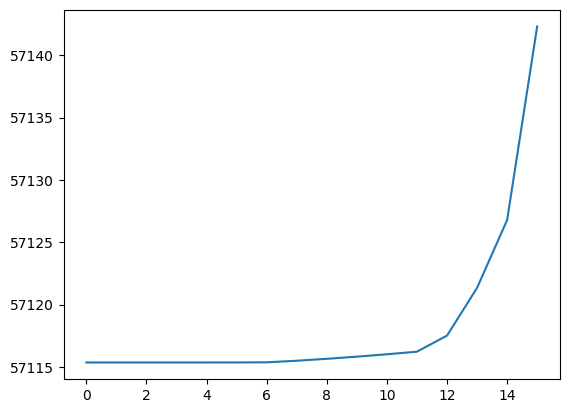

In [50]:
results_df.sort_values( by = ["Alpha"])["RMSE"].plot()

In [51]:
# Retrain the model w/ alpha = 50
my_fit_rr = Ridge(alpha = 1e-15)
my_fit_rr.fit(X_train, y_train)

# Calculate CV RMSE
results = cross_val_score(my_fit_rr, X_scaled, y_target, scoring='neg_root_mean_squared_error', cv = 10)
rmse = abs(results.mean())
print(f"CV RMSE: {rmse}")

CV RMSE: 57115.35937757189


In [52]:
# Multiple CV loop for Ridge with alpha=1e-15.
n = 100
results = np.zeros(n)

for i in range(n):
    X_train, X_test, y_train, y_test = train_test_split(
        X_scaled,
        y_target,
        test_size=0.25,
        random_state=None
    )

    # Create an empty LR model
    my_fit_rr = Ridge(alpha = 1e-15)

    # Train ( fit ) the model
    my_fit_rr.fit(X_train, y_train)

    # Make predicitons using the model
    y_pred = my_fit_rr.predict(X_test)

    # calculate the accuracy
    results[i] = metrics.r2_score(y_test, y_pred)

results

array([0.55053585, 0.41287231, 0.55273852, 0.54325043, 0.55507435,
       0.3914612 , 0.39108877, 0.48876932, 0.53146318, 0.50461418,
       0.53246741, 0.49044739, 0.50091591, 0.49712264, 0.52803739,
       0.44168813, 0.54203754, 0.55782401, 0.5470825 , 0.53405281,
       0.46557321, 0.52921185, 0.54131418, 0.54398799, 0.47835489,
       0.4007428 , 0.52688691, 0.58068711, 0.48014261, 0.59541939,
       0.48609656, 0.51391095, 0.53437607, 0.53159748, 0.35507141,
       0.54004626, 0.52621193, 0.42385127, 0.49513021, 0.49819502,
       0.50017857, 0.4955401 , 0.5898376 , 0.52814682, 0.51759749,
       0.3287744 , 0.47686466, 0.5263977 , 0.53972682, 0.55986158,
       0.47013225, 0.50855035, 0.44573292, 0.57309505, 0.50516428,
       0.51713203, 0.55639283, 0.5395959 , 0.55594751, 0.49331928,
       0.46891301, 0.58521954, 0.53717999, 0.34151227, 0.50385813,
       0.35267195, 0.38441512, 0.52813177, 0.5004504 , 0.51239196,
       0.49020903, 0.53231649, 0.55992456, 0.55939827, 0.54309

''

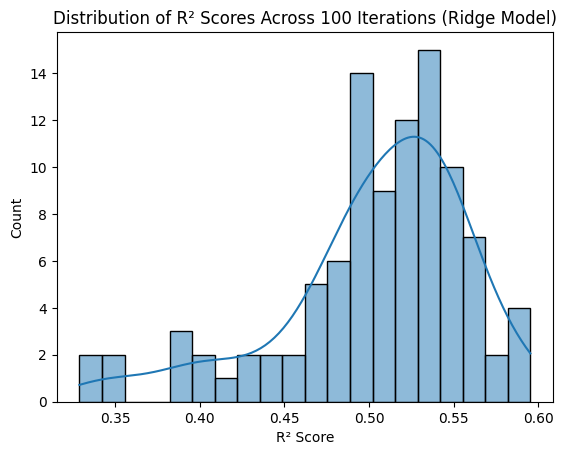

In [53]:
# Display a histogram of the multi CV results for Ridge with alpha=50.
sns.histplot(results, kde=True, bins=20)
plt.title('Distribution of R² Scores Across 100 Iterations (Ridge Model)')
plt.xlabel('R² Score')
plt.ylabel('Count')
;

## Data Visualization

#### Residual Analysis

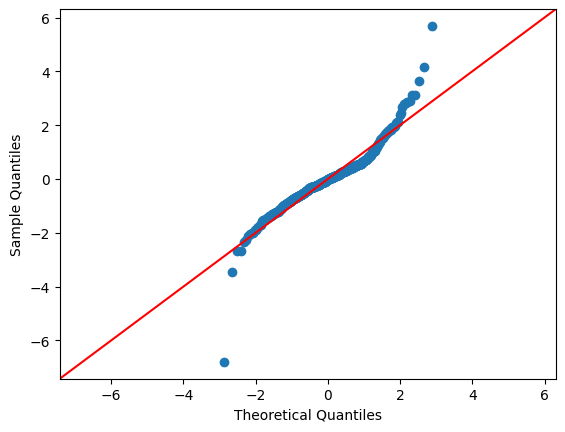

In [55]:
# QQ Plot - Residuals are not normally distributed
res = y_test[target_col] - y_pred
sm.qqplot(res, fit=True, line="45") ;

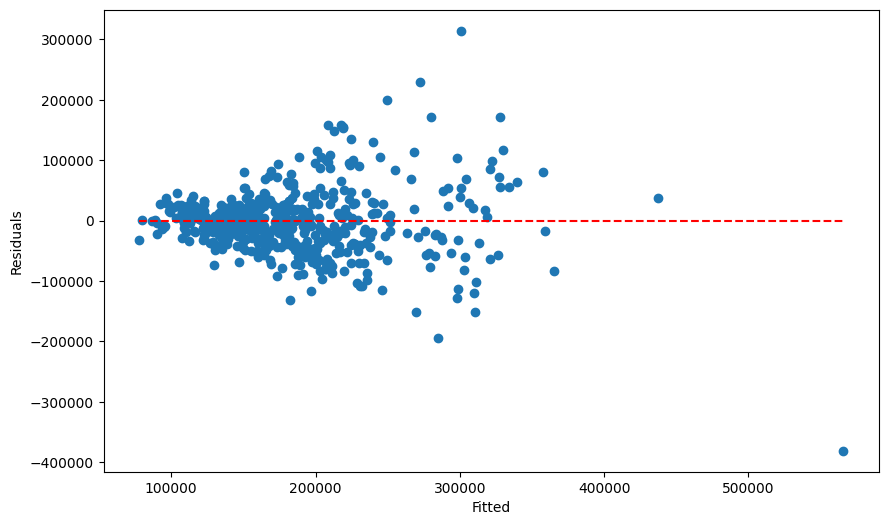

In [56]:
# Residuals vs Fitted (Predicted) Values - Constant variance
plt.figure(figsize = (10,6))
plt.scatter(y_pred, res)
plt.xlabel("Fitted")
plt.ylabel("Residuals")
plt.hlines(0, min(y_pred), max(y_pred), colors = 'red', linestyles = 'dashed') ;

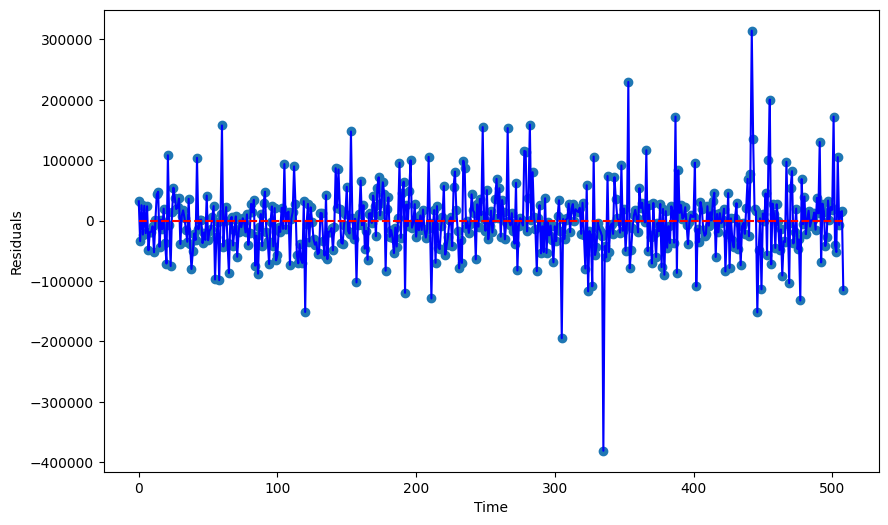

In [57]:
# Residuals vs Time - indepedence
plt.figure(figsize = (10,6))
plt.scatter(range(len(res)), res)
plt.plot(range(len(res)), res, 'b')
plt.xlabel("Time")
plt.ylabel("Residuals")
plt.hlines(0, min(range(len(res))), max(range(len(res))), colors = 'red', linestyles = 'dashed') ;

In [58]:
# Linear Regression - prediction peformance stats
print("Mean R²:", np.mean(results))
print("Standard deviation:", np.std(results))
print("Minimum R²:", np.min(results))
print("Maximum R²:", np.max(results))

Mean R²: 0.5039313381830367
Standard deviation: 0.05531747414341526
Minimum R²: 0.3287744044318458
Maximum R²: 0.5954193945123798


## Communication of Results

#### Conclusion

Mean R² for Ridge Regression Model: 0.5039313381830367

Selecting 1 feature using Ridge for feature selection, I chose 'Gr Liv Area' because it had the 2nd highest correlation with the target. I ran the one with the highest correlation in the last pass. The model performed slightly better than the previous pass, but the RMSE is still high.

#### Future Work
- Try a different model
- Try other features to try getting our the mean R2 to come down.